In [8]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("Ambiente:", sys.executable)

print("\nNotebook funcionando corretamente!")

Python: 3.15.0 (tags/v3.15.0:d220409, Oct  9 2026, 11:55:56) [MSC v.1951 64 bit (AMD64)]
Pandas: 3.0.6
Ambiente: c:\Users\Usuario\OneDrive\Documents\FIAP - Pós Graduação\Projeto - Pós Gradução 1° Semestre\.venv\Scripts\python.exe

Notebook funcionando corretamente!


# Análise Exploratória de Dados — Customer Churn

## FIAP — Tech Challenge | Machine Learning Engineering

### 1. Contexto do negócio

O cancelamento de clientes, conhecido como *Customer Churn*, representa um desafio para empresas de telecomunicações, pois pode comprometer a receita e aumentar os custos de aquisição de novos clientes.

Este projeto utiliza o dataset **Telco Customer Churn**, disponibilizado pela IBM, para investigar características associadas ao cancelamento de clientes.

### 2. Objetivo da análise

A análise exploratória busca:

- Compreender a estrutura e a qualidade dos dados.
- Identificar a proporção de clientes que cancelaram seus serviços.
- Investigar padrões de churn relacionados a contratos, pagamentos e serviços.
- Avaliar diferenças no tempo de permanência, cobranças mensais e CLTV.
- Produzir informações que apoiem a preparação dos dados e a modelagem preditiva.

### 3. Ferramentas utilizadas

- Python
- Pandas
- Matplotlib
- Jupyter Notebook

In [9]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [10]:
from pathlib import Path

PASTA_ATUAL = Path.cwd()

if (PASTA_ATUAL / "Telco_customer_churn.xlsx").exists():
    PASTA_PROJETO = PASTA_ATUAL
else:
    PASTA_PROJETO = PASTA_ATUAL.parent

CAMINHO_DATASET = PASTA_PROJETO / "Telco_customer_churn.xlsx"

df = pd.read_excel(CAMINHO_DATASET)

print("Dataset carregado com sucesso!")
print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

Dataset carregado com sucesso!
Quantidade de linhas: 7043
Quantidade de colunas: 33


In [11]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [12]:
print("Dimensões do dataset:", df.shape)

print("\nQuantidade de registros duplicados:")
print(df.duplicated().sum())

print("\nTipos das colunas:")
df.info()

Dimensões do dataset: (7043, 33)

Quantidade de registros duplicados:
0

Tipos das colunas:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str 

## 4. Análise da qualidade dos dados

Nesta etapa, verificamos a existência de valores ausentes e possíveis inconsistências no dataset.

Essa análise é importante para identificar problemas que precisam ser tratados antes do treinamento dos modelos de Machine Learning.

In [13]:
# Identificar valores ausentes

valores_ausentes = pd.DataFrame({
    "Valores ausentes": df.isna().sum(),
    "Percentual (%)": (df.isna().mean() * 100).round(2)
})

valores_ausentes = valores_ausentes[
    valores_ausentes["Valores ausentes"] > 0
].sort_values("Valores ausentes", ascending=False)

display(valores_ausentes)

,Valores ausentes,Percentual (%)
Churn Reason,5174,73.46


In [14]:
# Converter Total Charges temporariamente para numérico
# sem modificar o DataFrame original

total_charges_numerico = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)

print(
    "Quantidade de valores inválidos ou ausentes em Total Charges:",
    total_charges_numerico.isna().sum()
)

print("\nClientes com valores inválidos ou ausentes:")

display(
    df.loc[
        total_charges_numerico.isna(),
        ["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges"]
    ]
)

Quantidade de valores inválidos ou ausentes em Total Charges: 11

Clientes com valores inválidos ou ausentes:


,CustomerID,Tenure Months,Monthly Charges,Total Charges
2234,4472-LVYGI,0,52.55,
2438,3115-CZMZD,0,20.25,
2568,5709-LVOEQ,0,80.85,
2667,4367-NUYAO,0,25.75,
2856,1371-DWPAZ,0,56.05,
4331,7644-OMVMY,0,19.85,
4687,3213-VVOLG,0,25.35,
5104,2520-SGTTA,0,20.00,
5719,2923-ARZLG,0,19.70,
6772,4075-WKNIU,0,73.35,


## 5. Análise da variável-alvo — Churn

A variável `Churn Label` identifica se um cliente cancelou ou não os serviços da empresa.

- **No:** cliente que permaneceu.
- **Yes:** cliente que cancelou.

O objetivo desta análise é compreender a distribuição das classes e identificar possíveis desbalanceamentos que possam influenciar o treinamento dos modelos de Machine Learning.

In [15]:
# Distribuição absoluta e percentual do churn

churn_counts = df["Churn Label"].value_counts()

churn_percentual = (
    df["Churn Label"]
    .value_counts(normalize=True)
    .mul(100)
)

distribuicao_churn = pd.DataFrame({
    "Quantidade": churn_counts,
    "Percentual (%)": churn_percentual.round(2)
})

display(distribuicao_churn)

,Quantidade,Percentual (%)
Churn Label,,
No,5174,73.46
Yes,1869,26.54


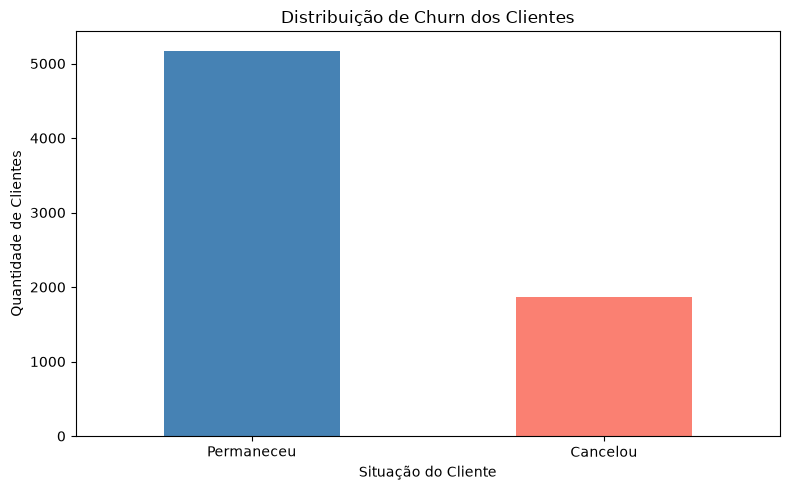

In [16]:
# Gráfico de distribuição do churn

plt.figure(figsize=(8, 5))

churn_counts.reindex(["No", "Yes"]).plot(
    kind="bar",
    color=["steelblue", "salmon"]
)

plt.title("Distribuição de Churn dos Clientes")
plt.xlabel("Situação do Cliente")
plt.ylabel("Quantidade de Clientes")
plt.xticks(
    ticks=[0, 1],
    labels=["Permaneceu", "Cancelou"],
    rotation=0
)

plt.tight_layout()
plt.show()

### 5.1. Interpretação dos resultados

A análise da variável-alvo revelou que:

- **5.174 clientes (73,46%)** permaneceram na empresa.
- **1.869 clientes (26,54%)** cancelaram seus serviços.

A distribuição demonstra um desbalanceamento entre as classes, com predominância de clientes que não cancelaram.

Esse comportamento exige atenção durante a avaliação dos modelos preditivos, pois a utilização isolada da acurácia pode produzir interpretações equivocadas sobre a capacidade de identificar clientes com risco de churn.

Por esse motivo, o projeto considera métricas adicionais, incluindo:

- **Precision:** proporção de previsões positivas que realmente representam cancelamentos.
- **Recall:** capacidade de identificar os clientes que efetivamente cancelaram.
- **F1-Score:** média harmônica entre Precision e Recall.
- **ROC-AUC:** capacidade de discriminação entre clientes que cancelam e permanecem, considerando diferentes limiares de classificação.

Essas métricas permitem uma avaliação mais abrangente do desempenho dos algoritmos de Machine Learning.

## 6. Análise de churn por tipo de contrato

Nesta etapa, investigamos a relação entre a modalidade contratual e a taxa de cancelamento dos clientes.

O objetivo é identificar diferenças no comportamento de churn entre contratos mensais, anuais e bienais.

In [17]:
# Taxa de churn por tipo de contrato

contract_churn = (
    pd.crosstab(
        df["Contract"],
        df["Churn Label"],
        normalize="index"
    )
    .mul(100)
)

display(contract_churn.round(2))

Churn Label,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


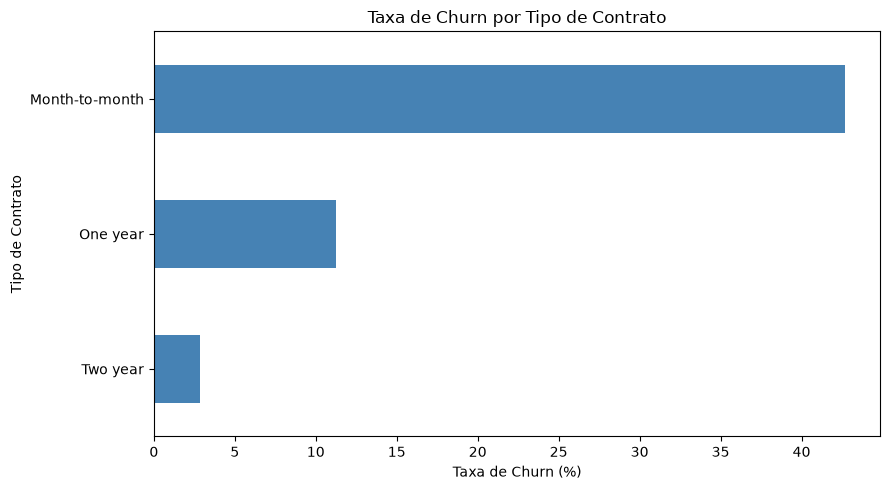

In [18]:
# Gráfico de churn por tipo de contrato

taxa_churn_contrato = contract_churn["Yes"].sort_values()

plt.figure(figsize=(9, 5))

taxa_churn_contrato.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Taxa de Churn por Tipo de Contrato")
plt.xlabel("Taxa de Churn (%)")
plt.ylabel("Tipo de Contrato")

plt.tight_layout()
plt.show()

### 6.1. Interpretação dos resultados

A análise demonstrou diferenças expressivas nas taxas de cancelamento entre as modalidades contratuais.

- **Contratos mensais:** aproximadamente 42,71% de churn.
- **Contratos anuais:** aproximadamente 11,27% de churn.
- **Contratos bienais:** aproximadamente 2,83% de churn.

Clientes com contratos mensais apresentam uma taxa de cancelamento significativamente superior à observada entre clientes com contratos de maior duração.

Esse resultado sugere uma associação entre a modalidade contratual e o comportamento de churn.

**Implicação para o negócio:** a empresa pode investigar estratégias de retenção direcionadas aos clientes com contratos mensais, como benefícios de fidelização e ofertas de migração para modalidades de maior duração.

**Observação:** essa análise demonstra associação estatística descritiva, não uma relação causal. Não é possível afirmar que a alteração do contrato, isoladamente, reduziria o cancelamento.

## 7. Análise de churn por método de pagamento

Nesta etapa, investigamos a relação entre os métodos de pagamento utilizados pelos clientes e suas respectivas taxas de cancelamento.

O objetivo é identificar possíveis diferenças no comportamento de churn entre clientes que utilizam pagamentos automáticos e outros métodos de pagamento.

In [19]:
# Taxa de churn por método de pagamento

payment_churn = (
    pd.crosstab(
        df["Payment Method"],
        df["Churn Label"],
        normalize="index"
    )
    .mul(100)
)

display(payment_churn.round(2))

Churn Label,No,Yes
Payment Method,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


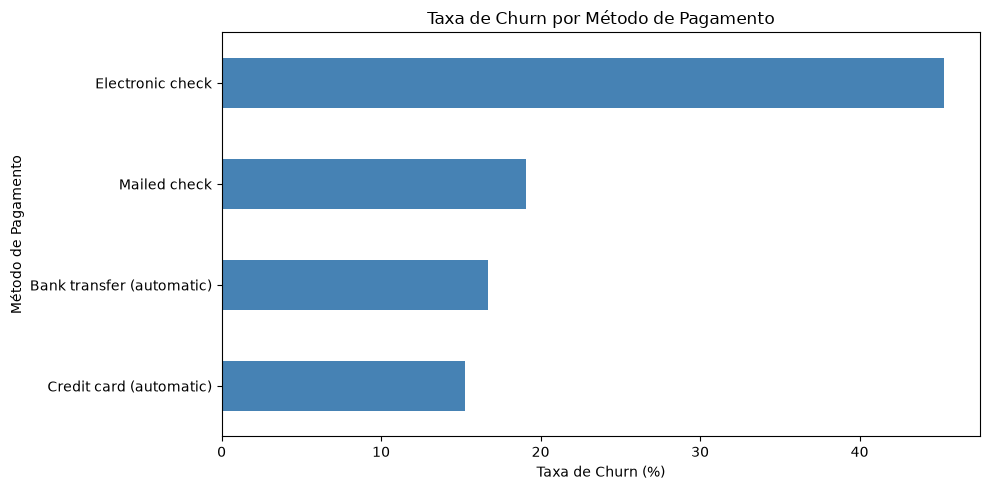

In [20]:
# Gráfico de churn por método de pagamento

taxa_churn_pagamento = payment_churn["Yes"].sort_values()

plt.figure(figsize=(10, 5))

taxa_churn_pagamento.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Taxa de Churn por Método de Pagamento")
plt.xlabel("Taxa de Churn (%)")
plt.ylabel("Método de Pagamento")

plt.tight_layout()
plt.show()

### 7.1. Interpretação dos resultados

A análise identificou diferenças nas taxas de cancelamento conforme o método de pagamento utilizado.

O método **Electronic check** apresentou uma taxa de churn de aproximadamente **45,29%**, indicando uma proporção elevada de cancelamentos nesse grupo.

Em comparação, clientes que utilizam **Credit card (automatic)** apresentaram uma taxa de cancelamento de aproximadamente **15,24%**.

Esses resultados sugerem uma associação entre o método de pagamento e o comportamento de churn.

**Implicação para o negócio:** a empresa pode investigar ações de retenção direcionadas aos clientes que utilizam Electronic check, além de avaliar possíveis benefícios associados à adesão a pagamentos automáticos.

**Observação:** os resultados não demonstram que o método de pagamento seja a causa do cancelamento. Outros fatores, como perfil do cliente e tipo de contrato, podem influenciar essa associação.

## 8. Análise de churn por serviço de internet

Nesta etapa, analisamos a relação entre o tipo de serviço de internet contratado e a taxa de cancelamento.

O objetivo é verificar se existem diferenças relevantes entre clientes que utilizam fibra óptica, DSL ou não possuem serviço de internet.

In [21]:
# Taxa de churn por tipo de serviço de internet

internet_churn = (
    pd.crosstab(
        df["Internet Service"],
        df["Churn Label"],
        normalize="index"
    )
    .mul(100)
)

display(internet_churn.round(2))

Churn Label,No,Yes
Internet Service,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


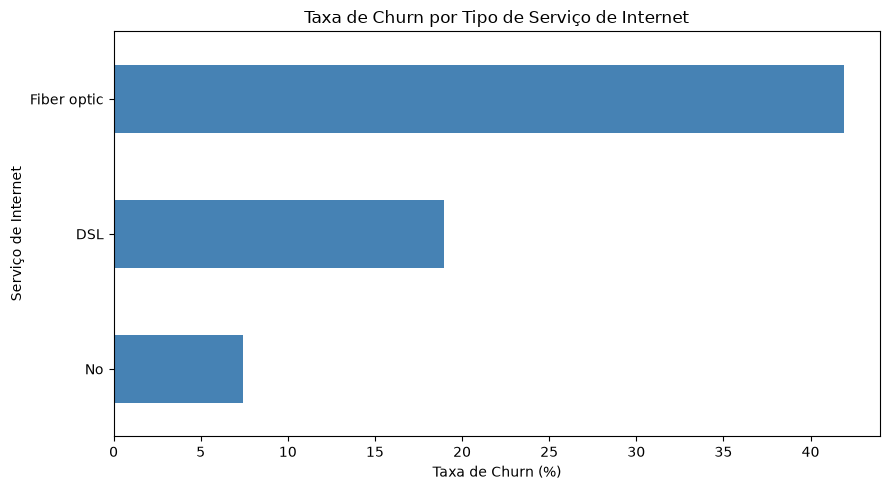

In [22]:
# Gráfico de churn por tipo de serviço de internet

taxa_churn_internet = internet_churn["Yes"].sort_values()

plt.figure(figsize=(9, 5))

taxa_churn_internet.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Taxa de Churn por Tipo de Serviço de Internet")
plt.xlabel("Taxa de Churn (%)")
plt.ylabel("Serviço de Internet")

plt.tight_layout()
plt.show()

### 8.1. Interpretação dos resultados

A análise demonstrou diferenças relevantes nas taxas de cancelamento conforme o serviço de internet contratado.

Os resultados observados foram:

- **Fiber optic:** aproximadamente 41,89% de churn.
- **DSL:** aproximadamente 18,96% de churn.
- **No:** aproximadamente 7,40% de churn.

Clientes com serviço de fibra óptica apresentaram a maior taxa de cancelamento entre os grupos analisados.

Esse comportamento sugere a necessidade de investigar possíveis fatores relacionados à experiência desses clientes, como preço, qualidade percebida do serviço, suporte técnico e características contratuais.

**Implicação para o negócio:** a empresa pode priorizar análises adicionais sobre clientes de fibra óptica, buscando identificar fatores associados à insatisfação e oportunidades de retenção.

**Observação:** a análise é descritiva e não permite concluir que a tecnologia de fibra óptica, isoladamente, provoque maior cancelamento.

## 9. Análise de churn por suporte técnico

Nesta etapa, investigamos a relação entre a contratação do serviço de suporte técnico e o cancelamento de clientes.

O objetivo é comparar as taxas de churn entre clientes que possuem suporte técnico, clientes que não possuem e clientes sem serviço de internet.

In [23]:
# Taxa de churn por disponibilidade de suporte técnico

tech_support_churn = (
    pd.crosstab(
        df["Tech Support"],
        df["Churn Label"],
        normalize="index"
    )
    .mul(100)
)

display(tech_support_churn.round(2))

Churn Label,No,Yes
Tech Support,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


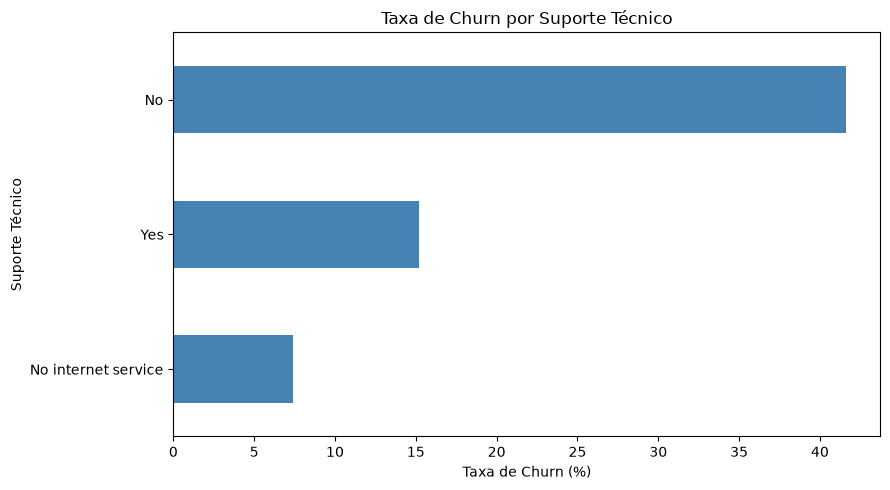

In [24]:
# Gráfico de churn por suporte técnico

taxa_churn_suporte = tech_support_churn["Yes"].sort_values()

plt.figure(figsize=(9, 5))

taxa_churn_suporte.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Taxa de Churn por Suporte Técnico")
plt.xlabel("Taxa de Churn (%)")
plt.ylabel("Suporte Técnico")

plt.tight_layout()
plt.show()

### 9.1. Interpretação dos resultados

A análise identificou diferenças relevantes nas taxas de cancelamento entre clientes com e sem suporte técnico.

Os resultados observados foram:

- **Sem suporte técnico:** aproximadamente 41,64% de churn.
- **Com suporte técnico:** aproximadamente 15,17% de churn.

Clientes que não possuem suporte técnico apresentam uma taxa de cancelamento consideravelmente superior à daqueles que contratam esse serviço.

**Implicação para o negócio:** a empresa pode investigar se a oferta de suporte técnico está associada a uma melhor experiência do cliente e avaliar oportunidades de retenção nesse segmento.

**Observação:** os resultados indicam associação, não causalidade. A contratação do suporte técnico pode estar relacionada a outras características dos clientes.

## 10. Análise de churn por segurança online

Nesta etapa, analisamos a relação entre a contratação do serviço de segurança online e a taxa de cancelamento.

O objetivo é identificar diferenças no comportamento de churn entre clientes que possuem ou não esse serviço.

In [25]:
# Taxa de churn por segurança online

security_churn = (
    pd.crosstab(
        df["Online Security"],
        df["Churn Label"],
        normalize="index"
    )
    .mul(100)
)

display(security_churn.round(2))

Churn Label,No,Yes
Online Security,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


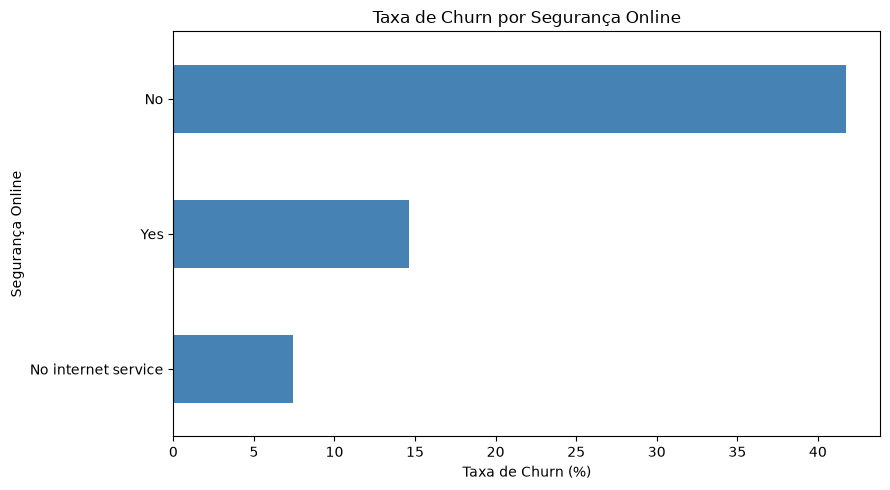

In [26]:
# Gráfico de churn por segurança online

taxa_churn_seguranca = security_churn["Yes"].sort_values()

plt.figure(figsize=(9, 5))

taxa_churn_seguranca.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Taxa de Churn por Segurança Online")
plt.xlabel("Taxa de Churn (%)")
plt.ylabel("Segurança Online")

plt.tight_layout()
plt.show()

### 10.1. Interpretação dos resultados

A análise identificou diferenças relevantes nas taxas de cancelamento conforme a contratação do serviço de segurança online.

Os resultados observados foram:

- **Sem segurança online:** aproximadamente 41,77% de churn.
- **Com segurança online:** aproximadamente 14,61% de churn.

Clientes que não possuem segurança online apresentam uma taxa de cancelamento superior à daqueles que contratam esse serviço.

**Implicação para o negócio:** a empresa pode investigar oportunidades de retenção relacionadas à oferta de serviços adicionais, especialmente para clientes com maior risco de cancelamento.

**Observação:** os resultados não permitem concluir que a contratação de segurança online, isoladamente, reduza a probabilidade de churn.

## 11. Análise do tempo de permanência

Nesta etapa, investigamos a relação entre o tempo de permanência dos clientes, medido em meses, e o comportamento de cancelamento.

O objetivo é verificar se existem diferenças na distribuição do tempo de permanência entre clientes que cancelaram e clientes que permaneceram.

In [27]:
# Estatísticas do tempo de permanência por churn

tenure_stats = (
    df.groupby("Churn Label")["Tenure Months"]
    .describe()
    .round(2)
)

display(tenure_stats)

,count,mean,std,min,25%,50%,75%,max
Churn Label,,,,,,,,
No,5174.0,37.57,24.11,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0


<Figure size 900x500 with 0 Axes>

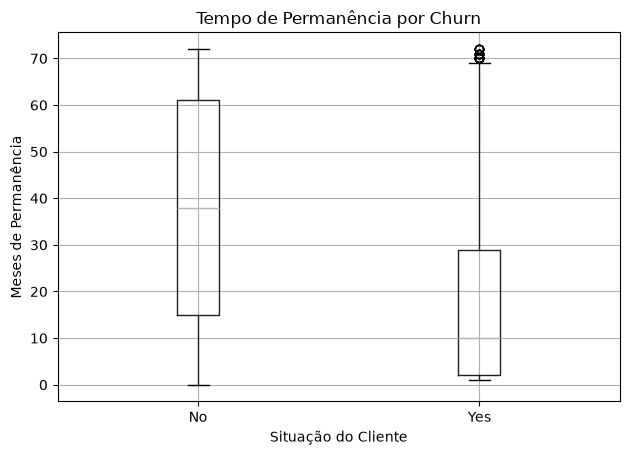

In [28]:
# Boxplot do tempo de permanência

plt.figure(figsize=(9, 5))

df.boxplot(
    column="Tenure Months",
    by="Churn Label"
)

plt.title("Tempo de Permanência por Churn")
plt.suptitle("")
plt.xlabel("Situação do Cliente")
plt.ylabel("Meses de Permanência")

plt.tight_layout()
plt.show()

### 11.1. Interpretação dos resultados

A análise revelou uma diferença relevante no tempo médio de permanência entre os grupos.

- **Clientes que cancelaram:** aproximadamente 17,98 meses.
- **Clientes que permaneceram:** aproximadamente 37,57 meses.

Os clientes que cancelaram apresentaram um tempo médio de permanência consideravelmente inferior ao dos clientes que permaneceram.

**Implicação para o negócio:** esse resultado sugere a importância de investigar estratégias de retenção nos primeiros meses de relacionamento, especialmente entre clientes com pouco tempo de contrato.

**Observação:** a análise é descritiva e não estabelece uma relação causal entre tempo de permanência e cancelamento.

## 12. Análise da cobrança mensal

Nesta etapa, investigamos a relação entre o valor da cobrança mensal dos clientes e o comportamento de cancelamento.

O objetivo é identificar diferenças na distribuição dos valores cobrados entre clientes que cancelaram e clientes que permaneceram.

In [29]:
# Estatísticas da cobrança mensal por churn

monthly_stats = (
    df.groupby("Churn Label")["Monthly Charges"]
    .describe()
    .round(2)
)

display(monthly_stats)

,count,mean,std,min,25%,50%,75%,max
Churn Label,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


<Figure size 900x500 with 0 Axes>

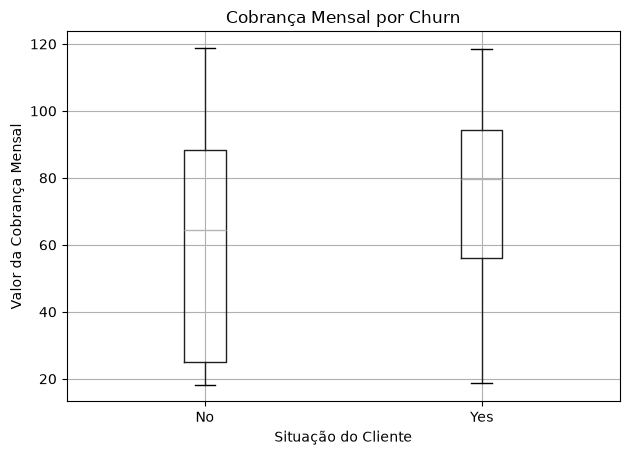

In [30]:
# Boxplot da cobrança mensal

plt.figure(figsize=(9, 5))

df.boxplot(
    column="Monthly Charges",
    by="Churn Label"
)

plt.title("Cobrança Mensal por Churn")
plt.suptitle("")
plt.xlabel("Situação do Cliente")
plt.ylabel("Valor da Cobrança Mensal")

plt.tight_layout()
plt.show()

### 12.1. Interpretação dos resultados

A análise identificou diferenças nos valores médios das cobranças mensais entre os grupos.

- **Clientes que cancelaram:** cobrança mensal média de aproximadamente 74,44.
- **Clientes que permaneceram:** cobrança mensal média de aproximadamente 61,27.

Os clientes que cancelaram apresentaram, em média, cobranças mensais superiores às dos clientes que permaneceram.

**Implicação para o negócio:** a empresa pode investigar a percepção de custo-benefício dos serviços contratados e avaliar estratégias de retenção para segmentos com mensalidades mais elevadas.

**Observação:** a diferença observada não demonstra que mensalidades mais altas sejam, isoladamente, a causa dos cancelamentos.

## 13. Análise de Customer Lifetime Value (CLTV)

Nesta etapa, investigamos a relação entre o Customer Lifetime Value (CLTV) e o comportamento de cancelamento.

O objetivo é comparar a distribuição do CLTV entre clientes que cancelaram e clientes que permaneceram, buscando compreender possíveis diferenças no valor econômico estimado desses grupos.

In [31]:
# Estatísticas do CLTV por churn

cltv_stats = (
    df.groupby("Churn Label")["CLTV"]
    .describe()
    .round(2)
)

display(cltv_stats)

,count,mean,std,min,25%,50%,75%,max
Churn Label,,,,,,,,
No,5174.0,4490.92,1167.70,2003.0,3643.75,4620.0,5434.75,6500.0
Yes,1869.0,4149.41,1189.37,2003.0,3101.00,4238.0,5166.00,6484.0


<Figure size 900x500 with 0 Axes>

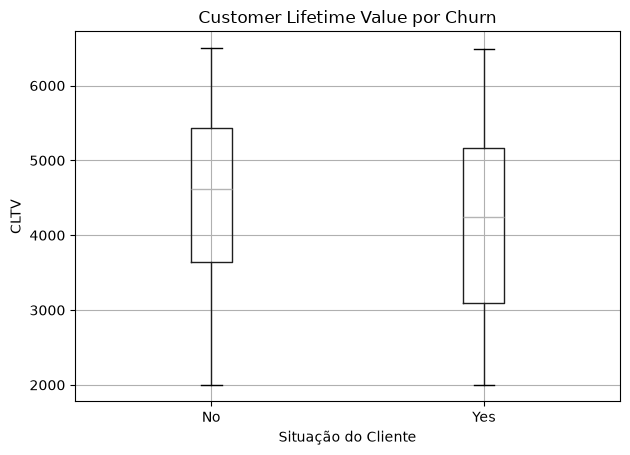

In [32]:
# Boxplot do CLTV

plt.figure(figsize=(9, 5))

df.boxplot(
    column="CLTV",
    by="Churn Label"
)

plt.title("Customer Lifetime Value por Churn")
plt.suptitle("")
plt.xlabel("Situação do Cliente")
plt.ylabel("CLTV")

plt.tight_layout()
plt.show()

### 13.1. Interpretação dos resultados

A análise identificou diferenças no CLTV médio entre clientes que cancelaram e clientes que permaneceram.

- **Clientes que cancelaram:** CLTV médio de aproximadamente 4.149,41.
- **Clientes que permaneceram:** CLTV médio de aproximadamente 4.490,92.

Os clientes que permaneceram apresentaram um CLTV médio superior ao dos clientes que cancelaram.

**Implicação para o negócio:** a combinação de informações sobre CLTV e probabilidade de churn pode apoiar a priorização de ações de retenção, especialmente quando a empresa precisa direcionar recursos para clientes com maior valor econômico estimado.

**Observação:** o CLTV representa uma estimativa de valor e não deve ser interpretado automaticamente como receita efetivamente perdida em decorrência do cancelamento.

## 14. Conclusões da Análise Exploratória

### 14.1. Principais descobertas

A análise exploratória do dataset Telco Customer Churn, composto por 7.043 clientes, permitiu identificar características associadas ao comportamento de cancelamento.

**1. Distribuição do churn**

Aproximadamente 26,54% dos clientes cancelaram seus serviços, enquanto 73,46% permaneceram. Essa distribuição demonstra um desbalanceamento entre as classes, considerado durante a avaliação dos modelos preditivos.

**2. Tipo de contrato**

Clientes com contratos mensais apresentaram uma taxa de churn de 42,71%, significativamente superior à observada em contratos anuais (11,27%) e bienais (2,83%).

Esse resultado indica que clientes com contratos de menor duração representam um segmento relevante para ações de retenção.

**3. Método de pagamento**

Clientes que utilizam Electronic check apresentaram uma taxa de cancelamento de aproximadamente 45,29%, enquanto aqueles com pagamento automático por cartão de crédito apresentaram 15,24%.

A diferença sugere uma associação entre o método de pagamento e o comportamento de churn.

**4. Serviço de internet**

Clientes com fibra óptica apresentaram uma taxa de churn de aproximadamente 41,89%, superior à observada entre clientes DSL (18,96%).

Esse resultado aponta para a importância de investigar fatores relacionados à experiência, ao preço e às características contratuais desses clientes.

**5. Suporte técnico e segurança online**

Clientes sem suporte técnico apresentaram uma taxa de churn de aproximadamente 41,64%, enquanto aqueles sem segurança online apresentaram 41,77%.

Essas diferenças sugerem oportunidades de investigação sobre a relação entre serviços adicionais, experiência do cliente e retenção.

**6. Tempo de permanência**

Clientes que cancelaram apresentaram tempo médio de permanência de 17,98 meses, enquanto aqueles que permaneceram apresentaram média de 37,57 meses.

Esse comportamento indica uma associação entre menor tempo de relacionamento e cancelamento.

**7. Cobrança mensal**

Clientes que cancelaram apresentaram cobrança mensal média de 74,44, superior à média de 61,27 observada entre os clientes que permaneceram.

A diferença sugere a importância de investigar a relação entre valor cobrado, serviços contratados e percepção de custo-benefício.

**8. Customer Lifetime Value (CLTV)**

O CLTV médio dos clientes que cancelaram foi de aproximadamente 4.149,41, enquanto o dos clientes que permaneceram foi de 4.490,92.

Essa informação pode contribuir para a priorização de estratégias de retenção, considerando tanto o risco de cancelamento quanto o valor econômico estimado dos clientes.

### 14.2. Contribuições para a modelagem preditiva

As descobertas da análise exploratória contribuíram para compreender as características do dataset e orientar as etapas seguintes do projeto.

Durante a preparação e a modelagem, foram considerados os seguintes aspectos:

* Tratamento de inconsistências identificadas na variável `Total Charges`.
* Exclusão de variáveis que poderiam provocar vazamento de informações (*data leakage*), como `Churn Reason` e `Churn Value`.
* Transformação de variáveis categóricas para utilização pelos algoritmos.
* Separação dos dados em conjuntos de treinamento e teste.
* Utilização de validação cruzada para comparar os modelos.
* Avaliação por diferentes métricas, incluindo Precision, Recall, F1-Score e ROC-AUC.

Foram avaliados três algoritmos de classificação: Regressão Logística, Random Forest e MLPClassifier.

A Regressão Logística foi selecionada como modelo campeão, considerando seu desempenho na validação cruzada, especialmente o F1-Score médio de aproximadamente 0,6213.

### 14.3. Recomendações de negócio

Com base nos padrões identificados, a empresa poderia investigar as seguintes oportunidades:

1. Desenvolver estratégias de retenção direcionadas aos clientes com contratos mensais.
2. Investigar fatores associados ao maior cancelamento entre clientes de fibra óptica.
3. Avaliar oportunidades de melhoria na experiência dos clientes sem suporte técnico.
4. Analisar a relação entre cobranças mensais, serviços contratados e percepção de valor.
5. Combinar as probabilidades previstas pelo modelo com informações de CLTV para apoiar a priorização de ações de retenção.

Essas recomendações representam hipóteses e oportunidades de investigação. As associações observadas na análise exploratória não demonstram relações causais.

### 14.4. Considerações finais

A análise exploratória permitiu compreender a estrutura do dataset, identificar inconsistências e reconhecer padrões associados ao cancelamento de clientes.

Os resultados forneceram subsídios para o desenvolvimento do pipeline de Machine Learning, desde a preparação dos dados até a comparação e seleção dos algoritmos.

O modelo preditivo desenvolvido poderá apoiar a identificação de clientes com maior probabilidade de churn, contribuindo para análises e estratégias de retenção orientadas por dados.

Entretanto, sua utilização em um ambiente real exigiria validação adicional, monitoramento de desempenho e avaliação dos impactos das ações de retenção.
